# Лабораторная работа №1. Метод обратного распространения ошибки

## 1. Загрузка и предобработка данных MNIST

Набор MNIST содержит 60 000 тренировочных и 10 000 тестовых изображений размера $28 \times 28$ в градациях серого с метками цифр от 0 до 9 (источник — датасет [hojjatk/mnist-dataset](https://www.kaggle.com/datasets/hojjatk/mnist-dataset) на Kaggle; формат файла `mnist.npz`).

Если локального файла `mnist.npz` рядом с ноутбуком нет, он скачивается по прямой ссылке. Разбор архива выполняется средствами NumPy — фреймворки глубокого обучения не используются.

In [1]:
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng(5543)
MNIST_URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"


def load_mnist():
    path = Path("mnist.npz")
    if not path.exists():
        print("Файл mnist.npz не найден — скачиваю.")
        tmp = Path(str(path) + ".part")
        urllib.request.urlretrieve(MNIST_URL, tmp)
        tmp.replace(path)
    with np.load(path, allow_pickle=False) as archive:
        return {name: archive[name] for name in archive.files}

data = load_mnist()
x_train_raw, y_train_raw = data["x_train"], data["y_train"]
x_test_raw, y_test_raw = data["x_test"], data["y_test"]

print("Количество примеров в обучающей выборке:", len(x_train_raw))
print("Количество примеров в тестовой выборке:  ", len(x_test_raw))
print("Форма одного изображения:", x_train_raw[0].shape)
print("Форма меток:", y_train_raw.shape, "| классы:", np.unique(y_train_raw).tolist())
print("Значения пикселей:", x_train_raw.dtype, "в диапазоне",
      x_train_raw.min(), "-", x_train_raw.max())

Файл mnist.npz не найден — скачиваю.


Количество примеров в обучающей выборке: 60000
Количество примеров в тестовой выборке:   10000
Форма одного изображения: (28, 28)
Форма меток: (60000,) | классы: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Значения пикселей: uint8 в диапазоне 0 - 255


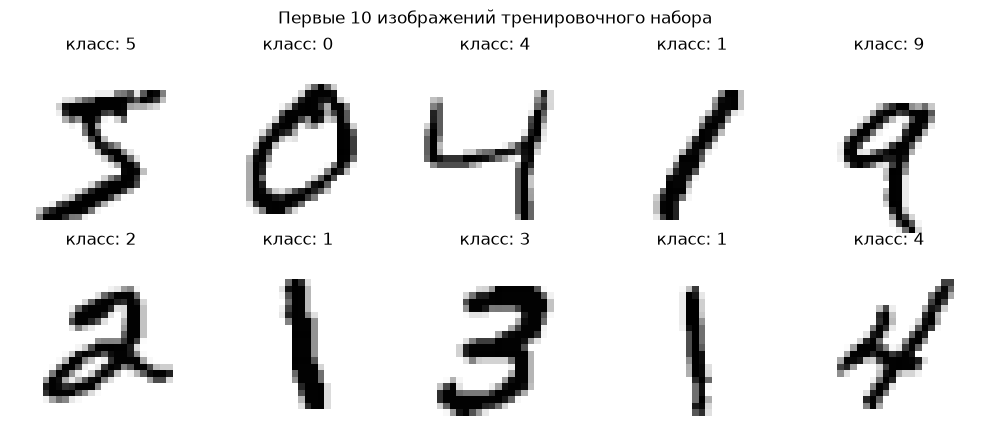

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, image, label in zip(axes.ravel(), x_train_raw[:10], y_train_raw[:10]):
    ax.imshow(image, cmap="gray_r")
    ax.set_title(f"класс: {label}")
    ax.axis("off")
plt.suptitle("Первые 10 изображений тренировочного набора")
plt.tight_layout()
plt.show()

Изображения и метки приводятся к виду, удобному для обучения:

1. Изображения 28 x 28 вытягиваются в векторы длиной 784 (вход полносвязной сети)
2. Пиксели нормируются делением на 255 — входы попадают в диапазон [0, 1]
3. Метки переводятся в one-hot кодировку, метка y -> вектор длины 10 с единицей на позиции y. В таком виде метки входят в формулу кросс-энтропии и градиента


In [3]:
X_train = x_train_raw.reshape(len(x_train_raw), -1).astype(np.float32) / 255.0
X_test = x_test_raw.reshape(len(x_test_raw), -1).astype(np.float32) / 255.0

Y_train = np.eye(10, dtype=np.float32)[y_train_raw]
Y_test = np.eye(10, dtype=np.float32)[y_test_raw]
y_train, y_test = y_train_raw, y_test_raw

print("X_train:", X_train.shape, X_train.dtype,
      "| диапазон:", float(X_train.min()), "-", float(X_train.max()))
print("X_test: ", X_test.shape, X_test.dtype)
print("Y_train:", Y_train.shape, Y_train.dtype)
print("Y_test: ", Y_test.shape, Y_test.dtype)
print("y_train:", y_train.shape, y_train.dtype, "| y_test:", y_test.shape, y_test.dtype)
print("Пример метки:", int(y_train_raw[0]), "-> one-hot:", Y_train[0].tolist())

X_train: (60000, 784) float32 | диапазон: 0.0 - 1.0
X_test:  (10000, 784) float32
Y_train: (60000, 10) float32
Y_test:  (10000, 10) float32
y_train: (60000,) uint8 | y_test: (10000,) uint8
Пример метки: 5 -> one-hot: [0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0]


## 2. Реализация нейронной сети

In [4]:
def init_params(n_in=784, n_hidden=300, n_out=10, rng=None):
    return {
        "W1": (rng.standard_normal((n_in, n_hidden)) * np.sqrt(2.0 / n_in)).astype(np.float32),
        "b1": np.zeros(n_hidden, dtype=np.float32),
        "W2": (rng.standard_normal((n_hidden, n_out)) * np.sqrt(2.0 / n_hidden)).astype(np.float32),
        "b2": np.zeros(n_out, dtype=np.float32),
    }


def relu(z):
    return np.maximum(z, 0.0)


def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def forward(params, x):
    z1 = x @ params["W1"] + params["b1"]
    h = relu(z1)
    z2 = h @ params["W2"] + params["b2"]
    p = softmax(z2)
    return z1, h, z2, p


def cross_entropy(p, y):
    return float(-np.mean(np.sum(y * np.log(np.clip(p, 1e-12, None)), axis=1)))

In [5]:
def backward(params, x, y, z1, h, p):
    batch = x.shape[0]
    delta2 = (p - y) / batch
    grad_w2 = h.T @ delta2
    grad_b2 = delta2.sum(axis=0)
    delta1 = (delta2 @ params["W2"].T) * (z1 > 0)
    grad_w1 = x.T @ delta1
    grad_b1 = delta1.sum(axis=0)
    return {"W1": grad_w1, "b1": grad_b1, "W2": grad_w2, "b2": grad_b2}


def sgd_step(params, grads, lr):
    for key in params:
        params[key] -= lr * grads[key]


def train_epoch(params, x, y, batch_size, lr, rng):
    n = len(x)
    order = rng.permutation(n)
    total_loss = 0.0
    for start in range(0, n, batch_size):
        idx = order[start:start + batch_size]
        xb, yb = x[idx], y[idx]
        z1, h, _, p = forward(params, xb)
        total_loss += cross_entropy(p, yb) * len(idx)
        grads = backward(params, xb, yb, z1, h, p)
        sgd_step(params, grads, lr)
    return total_loss / n


def predict(params, x):
    return forward(params, x)[3].argmax(axis=1)


def classification_error(params, x, labels):
    return 100.0 * np.mean(predict(params, x) != labels)

## 3. Обучение с контрольными параметрами

| Параметр | Значение |
|---|---|
| Число скрытых нейронов s | 300 |
| Скорость обучения learning_rate | 0.1 |
| Размер пачки batch_size | 64 |
| Количество эпох epochs | 20 |

In [6]:
S = 300
LEARNING_RATE = 0.1
BATCH_SIZE = 64
EPOCHS = 20

params = init_params(n_hidden=S, rng=rng)
print("Число параметров сети:", sum(v.size for v in params.values()))

history = []
total_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    epoch_start = time.perf_counter()
    epoch_loss = train_epoch(params, X_train, Y_train, BATCH_SIZE, LEARNING_RATE, rng)
    train_err = classification_error(params, X_train, y_train)
    epoch_time = time.perf_counter() - epoch_start
    history.append((epoch, epoch_loss, train_err))
    print(f"Эпоха {epoch:2d}/{EPOCHS} | время: {epoch_time:6.2f} с | "
          f"кросс-энтропия: {epoch_loss:.4f} | ошибка на train: {train_err:.2f}%")

total_time = time.perf_counter() - total_start
print(f"\nОбучение завершено за {total_time:.1f} с "
      f"(в среднем {total_time / EPOCHS:.2f} с на эпоху)")

Число параметров сети: 238510


Эпоха  1/20 | время:   6.08 с | кросс-энтропия: 0.3538 | ошибка на train: 6.68%


Эпоха  2/20 | время:   4.68 с | кросс-энтропия: 0.1843 | ошибка на train: 4.48%


Эпоха  3/20 | время:   2.20 с | кросс-энтропия: 0.1363 | ошибка на train: 3.13%


Эпоха  4/20 | время:   3.91 с | кросс-энтропия: 0.1093 | ошибка на train: 2.67%


Эпоха  5/20 | время:   3.97 с | кросс-энтропия: 0.0913 | ошибка на train: 2.31%


... (11 outputs left out)

Эпоха 17/20 | время:   0.95 с | кросс-энтропия: 0.0236 | ошибка на train: 0.40%


Эпоха 18/20 | время:   1.19 с | кросс-энтропия: 0.0217 | ошибка на train: 0.33%


Эпоха 19/20 | время:   1.92 с | кросс-энтропия: 0.0198 | ошибка на train: 0.24%


Эпоха 20/20 | время:   3.94 с | кросс-энтропия: 0.0183 | ошибка на train: 0.19%

Обучение завершено за 48.6 с (в среднем 2.43 с на эпоху)


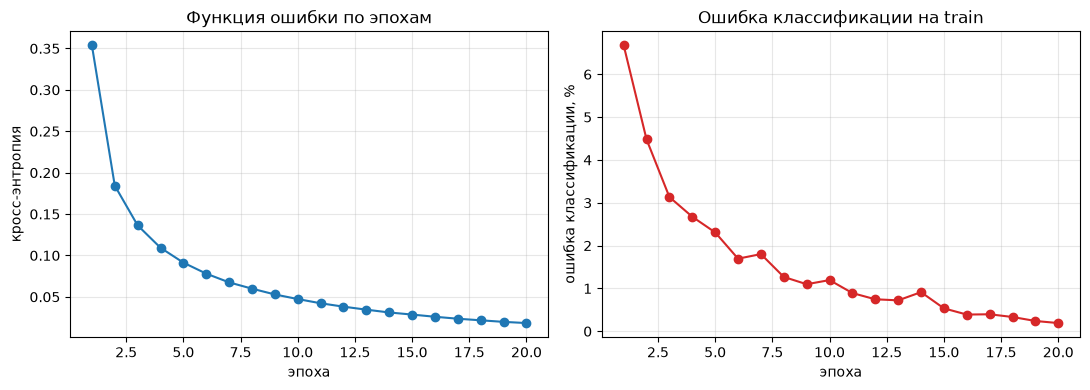

In [7]:
history_arr = np.asarray(history)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(history_arr[:, 0], history_arr[:, 1], marker="o")
ax1.set_xlabel("эпоха")
ax1.set_ylabel("кросс-энтропия")
ax1.set_title("Функция ошибки по эпохам")
ax1.grid(alpha=0.3)

ax2.plot(history_arr[:, 0], history_arr[:, 2], marker="o", color="tab:red")
ax2.set_xlabel("эпоха")
ax2.set_ylabel("ошибка классификации, %")
ax2.set_title("Ошибка классификации на train")
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
test_err = classification_error(params, X_test, y_test)
print(f"Ошибка классификации на тестовом наборе: {test_err:.2f}%")
print(f"Точность на тестовом наборе:              {100.0 - test_err:.2f}%")

Ошибка классификации на тестовом наборе: 1.92%
Точность на тестовом наборе:              98.08%


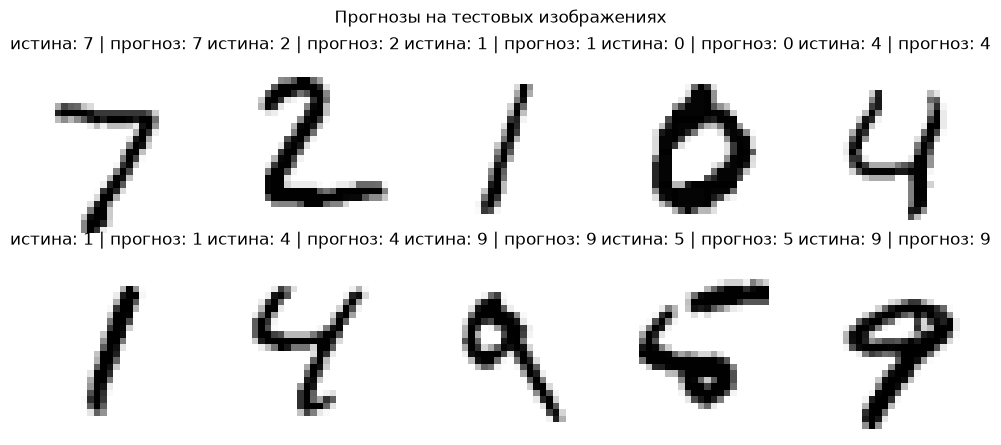

In [9]:
pred_test = predict(params, X_test)

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, image, true_label, pred_label in zip(
        axes.ravel(), x_test_raw[:10], y_test_raw[:10], pred_test[:10]):
    ax.imshow(image, cmap="gray_r")
    ax.set_title(f"истина: {true_label} | прогноз: {pred_label}", color="black")
    ax.axis("off")
plt.suptitle("Прогнозы на тестовых изображениях")
plt.tight_layout()
plt.show()